# 01 · Exploratory data analysis

Class balance by language and domain, train vs test mix, text lengths, style statistics, examples
of each class, and how ai/fusion texts relate to their human sources (needed for a leak-free validation split).

In [1]:
# Setup: clone/update the repo on Colab/Kaggle, install requirements, resolve paths, get the data
import os, sys, subprocess
REPO_URL = "https://github.com/anna-kryvulia/ucu-ai-hw-generated-text-detection.git"
BRANCH = "main"   # branch with the code you pushed
if "google.colab" in sys.modules or os.path.exists("/kaggle/working"):
    ROOT = "/content/repo" if "google.colab" in sys.modules else "/kaggle/working/repo"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{ROOT}/requirements.txt"], check=True)
else:
    ROOT = os.path.abspath("..")
sys.path.insert(0, f"{ROOT}/src")

from hwkit import env
from hwkit.download import ensure_data
P = env.setup(seed=42)
ensure_data(P)

platform: local
    data: /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/data
 outputs: /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/outputs
   cache: /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/outputs/cache
    repo: /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection
  device: mps
data ready at /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/data


PosixPath('/Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/data')

In [2]:
# Imports, figure folder, load train and test
import re
import textwrap
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

NOTEBOOK_START = time.time()
FIG = P.outputs / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160, "display.max_columns", 30)
LABELS = ["human", "fusion", "ai"]

train = pd.read_csv(P.data / "train.csv")
test = pd.read_csv(P.data / "test.csv")
for df in (train, test):
    df["domain_lang"] = df["domain"] + " | " + df["lang"]
print(train.shape, test.shape)
train.head(3).assign(text=lambda d: d["text"].str[:80])

(272352, 6) (25000, 5)


,id,text,lang,domain,label,domain_lang
0,e7adad,Diego's Demons Return: Is the Football Legend ...,en-EN,cnn_news,ai,cnn_news | en-EN
1,3bab63,Herr Präsident! Meine Damen und Herren! Es wir...,de-DE,bundestag,human,bundestag | de-DE
2,4e6c1f,Frau Präsidentin! Liebe Kolleginnen und Kolleg...,de-DE,bundestag,human,bundestag | de-DE


## Data quality

In [3]:
# Missing values, duplicate ids and texts, texts shared between train and test
checks = pd.DataFrame({
    "train": [train.isna().sum().sum(), train["id"].duplicated().sum(), train["text"].duplicated().sum(),
              train["text"].isin(set(test["text"])).sum()],
    "test": [test.isna().sum().sum(), test["id"].duplicated().sum(), test["text"].duplicated().sum(),
             test["text"].isin(set(train["text"])).sum()],
}, index=["missing values", "duplicate ids", "duplicate texts", "texts also in the other set"])
dup = train[train["text"].duplicated(keep=False)]
print("duplicated train texts with conflicting labels:", int(dup.groupby("text")["label"].nunique().gt(1).sum()))
checks

duplicated train texts with conflicting labels: 0


,train,test
missing values,0,0
duplicate ids,0,0
duplicate texts,0,0
texts also in the other set,0,0


**Findings.** No missing values, duplicates or texts shared between train and test, so no cleaning is needed.

## Class balance by language and domain

In [4]:
# Label counts overall, and label shares (rows sum to 1) by language and by domain
def shares(df, by):
    t = pd.crosstab(df[by], df["label"], normalize="index")[LABELS].round(3)
    t["rows"] = df[by].value_counts()
    return t.sort_values("rows", ascending=False)

print(train["label"].value_counts().to_string(), "\n")
display(shares(train, "lang"))
shares(train, "domain_lang")

label
ai        121940
fusion     83682
human      66730 



label,human,fusion,ai,rows
lang,,,,
en-EN,0.238,0.299,0.463,219581
de-DE,0.275,0.340,0.385,52771


label,human,fusion,ai,rows
domain_lang,,,,
student_essays | en-EN,0.231,0.370,0.399,54106
bundestag | de-DE,0.277,0.342,0.382,52343
cnn_news | en-EN,0.302,0.257,0.440,44285
blog_authorship_corpus | en-EN,0.307,0.306,0.387,40547
house_of_commons | en-EN,0.218,0.302,0.480,31859
euro_court_cases | en-EN,0.228,0.368,0.404,27578
arxiv_papers | en-EN,0.028,0.128,0.843,14290
gutenberg | en-EN,0.031,0.049,0.919,6916
gutenberg | de-DE,0.072,0.086,0.841,428


In [5]:
# Versions per source: fusion and ai texts per human text in each domain
c = pd.crosstab(train["domain_lang"], train["label"])
c[["fusion", "ai"]].div(c["human"], axis=0).round(2).sort_values("ai")

label,fusion,ai
domain_lang,,
blog_authorship_corpus | en-EN,0.99,1.26
bundestag | de-DE,1.24,1.38
cnn_news | en-EN,0.85,1.45
student_essays | en-EN,1.60,1.73
euro_court_cases | en-EN,1.62,1.77
house_of_commons | en-EN,1.38,2.20
gutenberg | de-DE,1.19,11.61
gutenberg | en-EN,1.58,29.44
arxiv_papers | en-EN,4.50,29.61


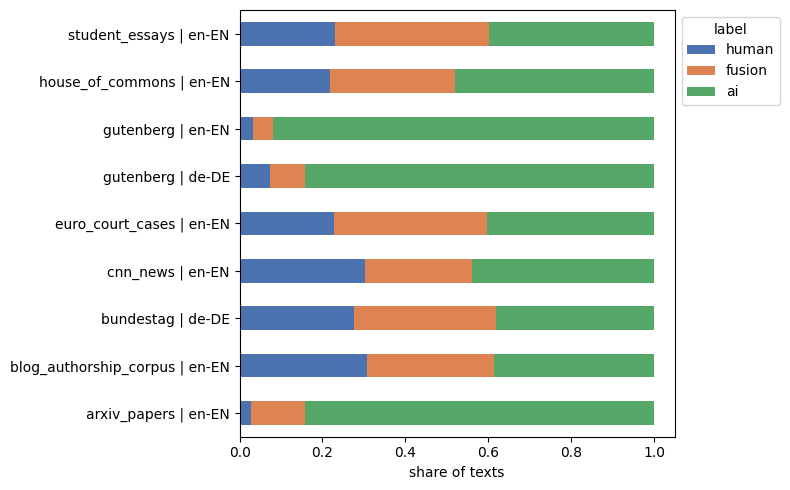

In [6]:
# Figure: label shares per domain and language
t = pd.crosstab(train["domain_lang"], train["label"], normalize="index")[LABELS]
ax = t.plot.barh(stacked=True, figsize=(8, 5), color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_xlabel("share of texts")
ax.set_ylabel("")
ax.legend(title="label", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(FIG / "eda_labels_by_domain.png", dpi=120)
plt.show()

**Findings.** ai is the largest class (45%) and human the smallest (25%). Macro-F1 weighs the three classes
equally, so class weights or tuned decision thresholds are worth testing. arxiv_papers and gutenberg are 84–92% ai:
there one human text has about 30 ai texts, so most ai texts have no human counterpart and the domain alone
predicts the label. In the other domains one human text has about 1–1.6 fusion and 1.3–2.2 ai versions.

## Train vs test mix

In [7]:
# Language and domain shares in train vs test (ratio > 1: the domain is more common in test)
def mix(col):
    m = pd.DataFrame({"train": train[col].value_counts(normalize=True),
                      "test": test[col].value_counts(normalize=True)}).fillna(0).round(3)
    m["ratio"] = (m["test"] / m["train"]).round(2)
    return m.sort_values("test", ascending=False)

display(mix("lang"))
mix("domain_lang")

,train,test,ratio
lang,,,
en-EN,0.806,0.853,1.06
de-DE,0.194,0.147,0.76


,train,test,ratio
domain_lang,,,
cnn_news | en-EN,0.163,0.197,1.21
blog_authorship_corpus | en-EN,0.149,0.178,1.19
student_essays | en-EN,0.199,0.159,0.80
bundestag | de-DE,0.192,0.143,0.74
house_of_commons | en-EN,0.117,0.118,1.01
gutenberg | en-EN,0.025,0.070,2.80
arxiv_papers | en-EN,0.052,0.067,1.29
euro_court_cases | en-EN,0.101,0.064,0.63
gutenberg | de-DE,0.002,0.004,2.00


**Findings.** Test has 2–3× more gutenberg and more arxiv, cnn_news and blogs, but fewer court cases, Bundestag
speeches and student essays (German: 15% of test vs 19% of train). Validation scores are therefore reweighted to the
test domain mix (see the split section).

## Text lengths

In [8]:
# Word and character counts; word-count summary per label
for df in (train, test):
    df["n_words"] = df["text"].str.count(r"\S+")
    df["n_chars"] = df["text"].str.len()
train.groupby("label")["n_words"].describe(percentiles=[.1, .5, .9]).loc[LABELS].round(0)

,count,mean,std,min,10%,50%,90%,max
label,,,,,,,,
human,66730.0,578.0,473.0,20.0,110.0,481.0,1105.0,2998.0
fusion,83682.0,585.0,531.0,20.0,137.0,445.0,1137.0,3000.0
ai,121940.0,493.0,294.0,20.0,126.0,465.0,872.0,2996.0


In [9]:
# Median words per domain: by label in train, and in test
med = train.pivot_table(index="domain_lang", columns="label", values="n_words", aggfunc="median")[LABELS]
med["test"] = test.groupby("domain_lang")["n_words"].median()
med.round(0)

label,human,fusion,ai,test
domain_lang,,,,
arxiv_papers | en-EN,2382.0,2344.0,824.0,843.0
blog_authorship_corpus | en-EN,137.0,128.0,129.0,125.0
bundestag | de-DE,585.0,584.0,429.0,458.0
cnn_news | en-EN,627.0,501.0,530.0,555.0
euro_court_cases | en-EN,854.0,764.0,550.0,628.0
gutenberg | de-DE,517.0,531.0,466.0,486.0
gutenberg | en-EN,1237.0,1586.0,707.0,688.0
house_of_commons | en-EN,554.0,509.0,547.0,535.0
student_essays | en-EN,388.0,343.0,371.0,331.0


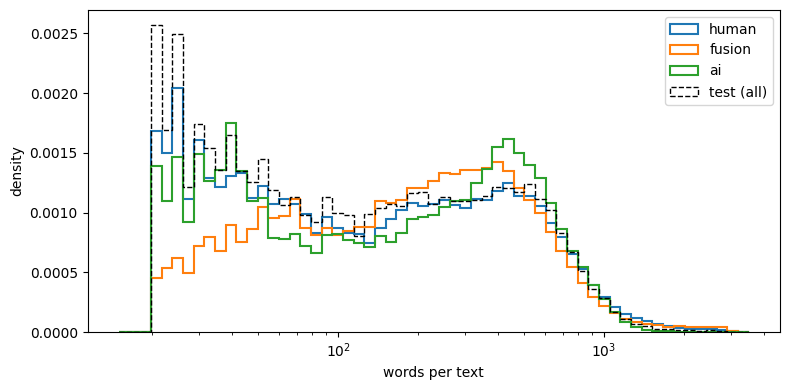

In [10]:
# Figure: word-count distribution per label (log x-axis), with the test set for comparison
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(np.log10(15), np.log10(3500), 60)
for lab in LABELS:
    ax.hist(train.loc[train["label"] == lab, "n_words"], bins=bins, histtype="step", density=True, lw=1.5, label=lab)
ax.hist(test["n_words"], bins=bins, histtype="step", density=True, color="k", ls="--", label="test (all)")
ax.set_xscale("log")
ax.set_xlabel("words per text")
ax.set_ylabel("density")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "eda_length_by_label.png", dpi=120)
plt.show()

In [11]:
# Share of texts longer than ~512 transformer tokens (roughly 380 words): these need truncation or chunking
long_share = pd.DataFrame({
    "train": train.groupby("lang")["n_words"].apply(lambda s: (s > 380).mean()),
    "test": test.groupby("lang")["n_words"].apply(lambda s: (s > 380).mean()),
}).round(3)
long_share.loc["all"] = [(train["n_words"] > 380).mean().round(3), (test["n_words"] > 380).mean().round(3)]
long_share

,train,test
lang,,
de-DE,0.768,0.655
en-EN,0.580,0.582
all,0.617,0.592


**Findings.** In arxiv, gutenberg (en) and court cases, human and fusion texts are much longer than ai texts, so
length is a shortcut there; the test medians of these domains are close to the ai medians. 62% of texts (77% of the
German ones) are longer than about 512 tokens: a transformer that reads only the beginning misses most of the text,
so the encoder has to read long texts in chunks.

## Style statistics: what differs between human, fusion and ai

In [12]:
# Simple style statistics on a fixed sample of 10k texts per label, mean per language and label
def ttr(s, n=200):
    """Type-token ratio on the first n words: unique words / words (vocabulary richness)."""
    w = re.findall(r"\w+", s.lower())[:n]
    return len(set(w)) / max(len(w), 1)

sample = train.sample(frac=1, random_state=42).groupby("label").head(10_000)
t, w = sample["text"], sample["n_words"]
sentences = t.str.count(r"[.!?]+(?:\s|$)").clip(lower=1)
letters = t.str.count(r"[^\W\d_]").clip(lower=1)
style = pd.DataFrame({
    "lang": sample["lang"],
    "label": sample["label"],
    "words_per_sentence": w / sentences,
    "chars_per_word": t.str.count(r"\w") / w,
    "type_token_ratio_200": t.map(ttr),
    "commas_per_100w": 100 * t.str.count(",") / w,
    "colons_semicolons_per_100w": 100 * t.str.count(r"[;:]") / w,
    "dashes_per_100w": 100 * t.str.count(r"[—–]| - ") / w,
    "quotes_per_100w": 100 * t.str.count(r"[\"“”„«»]") / w,
    "space_before_closing_quote_per_100w": 100 * t.str.count(r"[.!?,] [\"”'](?: |$)") / w,
    "digits_per_100w": 100 * t.str.count(r"\d") / w,
    "newlines_per_100w": 100 * t.str.count("\n") / w,
    "uppercase_share": t.str.count(r"[A-ZÄÖÜ]") / letters,
    "non_ascii_share": t.str.count(r"[^\x00-\x7F]") / t.str.len(),
})
order = pd.MultiIndex.from_product([sorted(style["lang"].unique()), LABELS])
style.groupby(["lang", "label"]).mean().reindex(order).T.round(3)

de-DE                   en-EN                
                                      human  fusion      ai   human  fusion      ai
words_per_sentence                   16.058  16.055  17.021  20.204  18.438  18.702
chars_per_word                        5.651   5.751   6.015   4.551   4.771   5.223
type_token_ratio_200                  0.689   0.681   0.703   0.608   0.625   0.674
commas_per_100w                       7.344   7.340   7.363   4.088   4.367   5.766
colons_semicolons_per_100w            1.061   0.884   0.592   0.598   0.463   0.627
dashes_per_100w                       0.991   0.789   0.326   0.177   0.149   0.365
quotes_per_100w                       0.377   0.308   0.313   0.492   0.486   0.928
space_before_closing_quote_per_100w   0.000   0.000   0.001   0.006   0.048   0.000
digits_per_100w                       2.151   1.604   0.481   5.984   5.365   1.552
newlines_per_100w                     0.000   0.000   0.000   0.000   0.000   0.000
uppercase_share                       0.057   0.056   0.054   0.037   0.031   0.027
non_ascii_share                       0.015   0.015   0.015   0.001   0.002   0.003

**Findings.** Compared with human texts, ai texts use longer words, a richer vocabulary, more quotes, more commas
(English) and about 4× fewer digits. Fusion lies between human and ai on almost every statistic but much closer to
human: it keeps the numbers, dashes and details of its source. One formatting trace is specific to English fusion
texts: a space between the final punctuation and a closing quote (`can. "` instead of `can."`), 8× more often than in
human texts and never in ai texts. Character n-grams should capture these signals; the hard part will be fusion vs
human. No text contains line breaks, so paragraph structure carries no signal.

## Examples of each class

In [13]:
# One example per label from two domains (first 400 characters)
for dom in ["cnn_news", "bundestag"]:
    for lab in LABELS:
        row = train[(train["domain"] == dom) & (train["label"] == lab)].sample(1, random_state=1).iloc[0]
        print(f"--- {dom} | {row['lang']} | {lab} | {row['n_words']} words")
        print(textwrap.fill(row["text"][:400], 120), "\n")

--- cnn_news | en-EN | human | 1251 words
JACKSON, Georgia (CNN) "I gave up smoking, women and drinkin' last night," the singer shouts, "and it was the worst 15
minutes of mah life!" The Rev. Joe Hunter hears all types of stories from drivers at his truck stop chapel. The music
blaring from the radio tonight is country. The dessert special is peach cobbler. And the customers are wide-bodied truck
drivers, lumbering into a Georgia truck st 

--- cnn_news | en-EN | fusion | 723 words
By . Larisa Brown . PUBLISHED: . 15:11 EST, 18 February 2014 . | . UPDATED: . 16:17 EST, 18 February 2014 . These are
the two ‘petite’ firearms officers set to receive payouts of £35,000 each after complaining their guns were too big for
their small hands. Pictured for the first time, Victoria Wheatley and Rachael Giles won a sex discrimination case on the
grounds they could not reach the trigger. 



--- cnn_news | en-EN | ai | 443 words
In a significant legal development, the United States Supreme Court has upheld the convictions of former Alabama
Governor Don Siegelman and HealthSouth CEO Richard Scrushy, reinforcing the judiciary's stance against public corruption
and bribery. The decision, which emerged from a case that has garnered national attention, underscores the court's
commitment to maintaining the integrity of public o 

--- bundestag | de-DE | human | 690 words
Frau Präsidentin! Sehr geehrte Damen und Herren! Genossin Giffey hat dem Genossen Finanzminister mit diesem Familienetat
gleich eine Freude gemacht; denn es war schließlich Olaf Scholz, der in der rot-grünen Regierung als Genosse
Generalsekretär die Ganztagsbetreuung als kulturelle Revolution gefordert hat. Er rief dazu auf, die staatliche
Lufthoheit über den Kinderbetten zu erobern. Bei der Erobe 

--- bundestag | de-DE | fusion | 648 words
Einen schönen guten Abend an alle! Sehr geehrter Herr Präsident! Wir we

--- bundestag | de-DE | ai | 441 words
Liebe Kolleginnen und Kollegen, heute möchte ich Sie zu einem Thema bitten, das uns alle bewegen sollte: Der humanitären
Katastrophe in Jemen. Es ist ein Konflikt, der seit Jahren unsere Welterschütterung auslöst, ein Albtraum, in dem Kinder
zum Kriegsgeschehen gezwungen werden und Millionen Menschen an Hunger, Krankheiten und Gewalt sterben. Seit 2014 tobte
dieser Krieg im Land, verursacht durch 



## Linking ai/fusion texts to their human source

A human text and its ai/fusion versions are always on the same side of the train/test split, but there is no
column that links them. Probe on one domain: for ai and fusion texts, find the most similar human text by TF-IDF
cosine similarity, and compare with the similarity between unrelated human texts of the same domain.

In [14]:
# TF-IDF of the human texts in one domain, and of 2,000 fusion + 2,000 ai texts from it
PROBE = "cnn_news | en-EN"
dom = train[train["domain_lang"] == PROBE]
hum = dom[dom["label"] == "human"]
queries = dom[dom["label"] != "human"].sample(frac=1, random_state=42).groupby("label").head(2000)
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=300_000, sublinear_tf=True)
H = vec.fit_transform(hum["text"])
Q = vec.transform(queries["text"])
print(f"{PROBE}: {H.shape[0]} human texts, queries: {queries['label'].value_counts().to_dict()}")

cnn_news | en-EN: 13395 human texts, queries: {'fusion': 2000, 'ai': 2000}


In [15]:
# Most similar and second most similar human text for every query (cosine similarity, in chunks)
def nearest(Q, H, self_idx=None, chunk=500):
    best, second, arg = [], [], []
    for i in range(0, Q.shape[0], chunk):
        S = (Q[i:i + chunk] @ H.T).toarray()
        rows = np.arange(S.shape[0])
        if self_idx is not None:                       # a human text must not match itself
            S[rows, self_idx[i:i + chunk]] = -1
        top = np.argsort(-S, axis=1)[:, :2]
        best.append(S[rows, top[:, 0]])
        second.append(S[rows, top[:, 1]])
        arg.append(top[:, 0])
    return np.concatenate(best), np.concatenate(second), np.concatenate(arg)

b, s, a = nearest(Q, H)
probe = pd.DataFrame({"kind": queries["label"].values + " → nearest human", "best": b, "second": s, "human_idx": a})
ref_idx = np.random.default_rng(42).choice(H.shape[0], min(2000, H.shape[0]), replace=False)
b, s, _ = nearest(H[ref_idx], H, self_idx=ref_idx)
probe = pd.concat([probe, pd.DataFrame({"kind": "human → nearest other human", "best": b, "second": s})])
probe["gap"] = probe["best"] - probe["second"]
probe.groupby("kind")[["best", "gap"]].quantile([.1, .5, .9]).unstack().round(3)

best                  gap              
                               0.1    0.5    0.9    0.1    0.5    0.9
kind                                                                 
ai → nearest human           0.112  0.165  0.233  0.009  0.053  0.114
fusion → nearest human       0.615  0.788  0.918  0.466  0.650  0.794
human → nearest other human  0.085  0.127  0.235  0.002  0.011  0.065

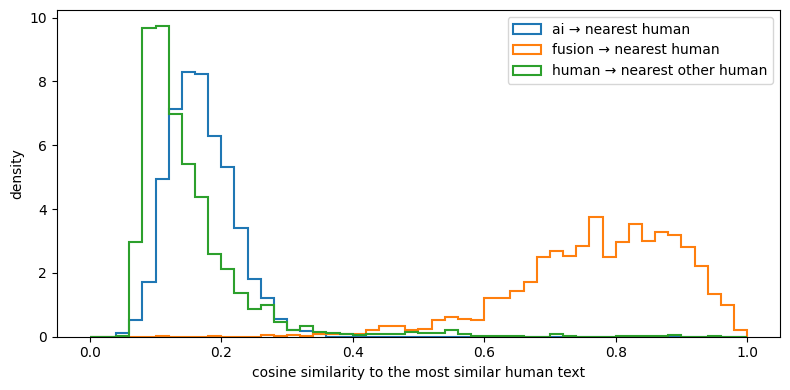

In [16]:
# Figure: similarity to the nearest human text, per kind of query
fig, ax = plt.subplots(figsize=(8, 4))
for kind, g in probe.groupby("kind"):
    ax.hist(g["best"], bins=50, range=(0, 1), histtype="step", density=True, lw=1.5, label=kind)
ax.set_xlabel("cosine similarity to the most similar human text")
ax.set_ylabel("density")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "eda_source_similarity.png", dpi=120)
plt.show()

In [17]:
# Side by side: the most and least similar fusion text and its nearest human text (first 300 characters)
fus = probe[probe["kind"].str.startswith("fusion")].reset_index(drop=True)
fus_q = queries[queries["label"] == "fusion"].reset_index(drop=True)
for name, i in [("most similar", fus["best"].idxmax()), ("least similar", fus["best"].idxmin())]:
    print(f"=== {name}: cosine {fus.loc[i, 'best']:.3f}")
    print("FUSION:", textwrap.fill(fus_q.loc[i, "text"][:300], 120))
    print("HUMAN: ", textwrap.fill(hum.iloc[int(fus.loc[i, "human_idx"])]["text"][:300], 120), "\n")

=== most similar: cosine 0.990
FUSION: (CNN) Peter Bogdanovich would like to thank a man he never met. The man's name was James Blakely, and he was a member of
the editorial department at 20th Century Fox. He loved musicals and Cole Porter, and was primed to like "At Long Last
Love," Bogdanovich's Porter-infused musical. After the 1975 f
HUMAN:  (CNN) Peter Bogdanovich would like to thank a man he never met. The man's name was James Blakely, and he was a member of
the editorial department at 20th Century Fox. He loved musicals and Cole Porter, and was primed to like "At Long Last
Love," Bogdanovich's Porter-infused musical. After the 1975 f 

=== least similar: cosine 0.120
FUSION: These protests, fueled by a deep yearning for democratic freedoms and human rights, represent the Iranian people’s
courageous defiance against an oppressive regime. While the government continues to silence dissent with brutal
crackdowns, the spirit of resistance burns brightly, echoing across socia
HUMAN:  

In [18]:
# Where does a fusion text differ from its human source? Word-level diff at three similarity levels
import difflib

def diff_summary(fusion, human, show=3, width=150):
    wf, wh = fusion.split(), human.split()
    sm = difflib.SequenceMatcher(None, wh, wf, autojunk=False)
    copied = sum(m.size for m in sm.get_matching_blocks()) / len(wf)
    changes = [op for op in sm.get_opcodes() if op[0] != "equal"]
    print(f"words: fusion {len(wf)}, human {len(wh)}; fusion words copied from the human text: {copied:.0%}")
    print("changed spans start at (share of the fusion text):", [round(j1 / len(wf), 2) for _, _, _, j1, _ in changes][:12])
    for tag, i1, i2, j1, j2 in changes[:show]:
        print(f"  [{tag}] HUMAN: '{' '.join(wh[i1:i2])[:width]}'")
        print(f"  {' ' * (len(tag) + 2)} FUSION: '{' '.join(wf[j1:j2])[:width]}'")

print(f"fusion texts with similarity < 0.3: {(fus['best'] < 0.3).mean():.1%}, < 0.5: {(fus['best'] < 0.5).mean():.1%}")
median_i = (fus["best"] - fus["best"].median()).abs().idxmin()
for name, i in [("most similar", fus["best"].idxmax()), ("median", median_i), ("least similar", fus["best"].idxmin())]:
    print(f"\n=== {name}: cosine {fus.loc[i, 'best']:.3f}")
    diff_summary(fus_q.loc[i, "text"], hum.iloc[int(fus.loc[i, "human_idx"])]["text"])

fusion texts with similarity < 0.3: 0.2%, < 0.5: 3.2%

=== most similar: cosine 0.990
words: fusion 1072, human 1052; fusion words copied from the human text: 95%
changed spans start at (share of the fusion text): [0.08, 0.1, 0.22, 0.27, 0.35, 0.39, 0.53, 0.53, 0.55, 0.63, 0.63, 0.64]
  [replace] HUMAN: 'it.''
            FUSION: 'it. ''
  [replace] HUMAN: 'can."'
            FUSION: 'can. "'
  [replace] HUMAN: 'Me)."'
            FUSION: 'Me). "'

=== median: cosine 0.788
words: fusion 954, human 1321; fusion words copied from the human text: 87%
changed spans start at (share of the fusion text): [0.06, 0.07, 0.32, 0.34, 0.38, 0.42, 0.42, 0.43, 0.45, 0.46, 0.47, 0.58]
  [replace] HUMAN: 'then-U.S.'
            FUSION: 'then-U. S.'
  [replace] HUMAN: 'worst."'
            FUSION: 'worst. "'
  [replace] HUMAN: 'combatants."'
            FUSION: 'combatants. "'

=== least similar: cosine 0.120
words: fusion 96, human 217; fusion words copied from the human text: 42%
changed spans start a

**Findings.** A fusion text is an edited copy of one human text: its nearest human text has a median cosine
similarity of 0.79, far above unrelated human pairs (0.13), and only 3% of fusion texts are below 0.5. Edits are
spread over the whole text, not only its end: the example with median similarity keeps 87% of the source words, and many
edits are tiny (spacing around punctuation). The range is wide, from near copies (95% of words kept) to full rewrites
(similarity 0.12) that read like ai, so fusion overlaps with human at one end and with ai at the other. ai texts are
new texts on the same topic and share few words with any human text (median 0.17).

## Source groups and a fixed validation split

Texts of one source (a human text and its fusion/ai versions) are on the same side of the train/test split, so they
must also stay on one side of the train/validation split. Otherwise the model sees the human original in training
and its edited copy in validation, and the validation score is too optimistic.

1. In each domain and language, find the most similar human text for every text (TF-IDF cosine).
2. Link a fusion or ai text to that human text if the similarity is at least 0.4, and a human text to another
   human text if it is at least 0.5 (near-copies: excerpts of one book, one court case, duplicated essays).
   Unrelated human texts are below 0.3 in 90% of cases. A wrong link only puts unrelated texts in one group, which
   is harmless; a missed link can leak.
3. Source groups are the connected components of these links.
4. Split the groups into 10 folds, stratified by domain, language and label; fold 0 is the fixed validation set.
5. Weight validation texts so the domain mix matches test (`weight`); report macro-F1 with and without weights.
6. Fix a 40k training subsample for transformer experiments (`sub40k`).

In [19]:
# Most similar human text for every text in the same domain and language; strong matches become links
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

LINK_SOURCE, LINK_HUMAN = 0.4, 0.5      # fusion/ai -> human, human -> other human

def top1(Q, H, self_idx=None, chunk=1000):
    """Best cosine similarity of each row of Q to the rows of H, and the index of that row."""
    best, arg = [], []
    for i in range(0, Q.shape[0], chunk):
        S = (Q[i:i + chunk] @ H.T).toarray()
        rows = np.arange(S.shape[0])
        if self_idx is not None:                       # a human text must not match itself
            S[rows, self_idx[i:i + chunk]] = -1
        a = S.argmax(axis=1)
        best.append(S[rows, a])
        arg.append(a)
    return np.concatenate(best), np.concatenate(arg)

assert isinstance(train.index, pd.RangeIndex), "row positions are used as node ids"
edges, link_stats = [], []
t0 = time.time()
for dl, d in train.groupby("domain_lang"):
    hum_d, qry_d = d[d["label"] == "human"], d[d["label"] != "human"]
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.5, max_features=300_000,
                          sublinear_tf=True, dtype=np.float32)
    H = vec.fit_transform(hum_d["text"])
    hb, ha = top1(H, H, self_idx=np.arange(H.shape[0]))
    qb, qa = top1(vec.transform(qry_d["text"]), H)
    h_pos, q_pos = hum_d.index.to_numpy(), qry_d.index.to_numpy()
    edges += [np.c_[h_pos[hb >= LINK_HUMAN], h_pos[ha[hb >= LINK_HUMAN]]],
              np.c_[q_pos[qb >= LINK_SOURCE], h_pos[qa[qb >= LINK_SOURCE]]]]
    is_fusion = (qry_d["label"] == "fusion").to_numpy()
    link_stats.append({"domain_lang": dl, "humans": len(hum_d), "fusion linked": (qb[is_fusion] >= LINK_SOURCE).mean(),
                       "ai linked": (qb[~is_fusion] >= LINK_SOURCE).mean(),
                       "human linked to a human": (hb >= LINK_HUMAN).mean(),
                       "fusion median sim": np.median(qb[is_fusion]), "minutes": (time.time() - t0) / 60})
edges = np.concatenate(edges)
pd.DataFrame(link_stats).round(3)

,domain_lang,humans,fusion linked,ai linked,human linked to a human,fusion median sim,minutes
0,arxiv_papers | en-EN,407,0.358,0.000,0.020,0.159,0.364
1,blog_authorship_corpus | en-EN,12466,0.952,0.028,0.015,0.775,0.980
2,bundestag | de-DE,14479,0.969,0.001,0.002,0.732,2.979
3,cnn_news | en-EN,13395,0.992,0.000,0.016,0.787,4.599
4,euro_court_cases | en-EN,6277,0.911,0.000,0.128,0.751,5.479
5,gutenberg | de-DE,31,0.838,0.067,0.710,0.874,5.484
6,gutenberg | en-EN,216,0.721,0.001,0.028,0.754,5.588
7,house_of_commons | en-EN,6953,0.801,0.006,0.044,0.666,6.425
8,student_essays | en-EN,12506,0.913,0.000,0.062,0.676,7.710


In [20]:
# Source groups: connected components of the links (a text without links is a group of its own)
graph = coo_matrix((np.ones(len(edges)), (edges[:, 0], edges[:, 1])), shape=(len(train), len(train)))
n_groups, train["group"] = connected_components(graph, directed=False)
sizes = train["group"].value_counts()
print(f"{n_groups} groups; groups by size: {sizes.value_counts().sort_index().head(8).to_dict()}")
print("largest groups (domain, size):", [(train.loc[train["group"] == g, "domain_lang"].iloc[0], n)
                                         for g, n in sizes.head(5).items()])

193705 groups; groups by size: {1: 139662, 2: 34281, 3: 17476, 4: 1304, 5: 375, 6: 392, 7: 84, 8: 37}
largest groups (domain, size): [('euro_court_cases | en-EN', 38), ('euro_court_cases | en-EN', 35), ('euro_court_cases | en-EN', 30), ('euro_court_cases | en-EN', 29), ('house_of_commons | en-EN', 26)]


In [21]:
# 10 group folds stratified by domain, language and label; fold 0 is the fixed validation set
fold = np.full(len(train), -1)
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
for k, (_, idx) in enumerate(sgkf.split(train, train["domain_lang"] + " | " + train["label"], train["group"])):
    fold[idx] = k
train["fold"] = fold
val = train["fold"] == 0
assert train.groupby("group")["fold"].nunique().max() == 1, "a group is split between folds"
print(f"validation: {val.sum()} texts ({val.mean():.1%}), {train.loc[val, 'group'].nunique()} groups")
pd.crosstab(np.where(val, "validation", "training part"), train["label"], normalize="index")[LABELS].round(3)

validation: 27236 texts (10.0%), 19368 groups


label,human,fusion,ai
row_0,,,
training part,0.245,0.307,0.448
validation,0.245,0.307,0.448


In [22]:
# Test-like weights: a text counts in proportion to how much more common its domain is in test than in its part
test_share = test["domain_lang"].value_counts(normalize=True)
train["weight"] = 0.0
for part in (val, ~val):
    own_share = train.loc[part, "domain_lang"].value_counts(normalize=True)
    train.loc[part, "weight"] = train.loc[part, "domain_lang"].map(test_share / own_share)
pd.DataFrame({
    "training part": train.loc[~val, "domain_lang"].value_counts(normalize=True),
    "validation": train.loc[val, "domain_lang"].value_counts(normalize=True),
    "validation weighted": train[val].groupby("domain_lang")["weight"].sum() / train.loc[val, "weight"].sum(),
    "test": test_share,
}).round(3).sort_values("test", ascending=False)

,training part,validation,validation weighted,test
domain_lang,,,,
cnn_news | en-EN,0.163,0.163,0.197,0.197
blog_authorship_corpus | en-EN,0.149,0.149,0.178,0.178
student_essays | en-EN,0.199,0.199,0.159,0.159
bundestag | de-DE,0.192,0.192,0.143,0.143
house_of_commons | en-EN,0.117,0.117,0.118,0.118
gutenberg | en-EN,0.025,0.025,0.070,0.070
arxiv_papers | en-EN,0.052,0.052,0.067,0.067
euro_court_cases | en-EN,0.101,0.101,0.064,0.064
gutenberg | de-DE,0.002,0.002,0.004,0.004


In [23]:
# Fixed 40k training subsample (outside validation, same domain/label mix), then save the split into the repo
frac = 40_000 / (~val).sum()
sub_ids = train[~val].groupby(["domain_lang", "label"]).sample(frac=frac, random_state=42)["id"]
train["sub40k"] = train["id"].isin(sub_ids)
SPLIT = P.repo / "results" / "split.csv.gz"
train[["id", "group", "fold", "weight", "sub40k"]].assign(weight=lambda d: d["weight"].round(5)).to_csv(SPLIT, index=False)
print(f"saved {SPLIT.name}: {SPLIT.stat().st_size / 1e6:.1f} MB; subsample {train['sub40k'].sum()} texts")

saved split.csv.gz: 2.4 MB; subsample 40002 texts


**Findings.** 72–99% of fusion texts are linked to a human source in every domain except arxiv (36%): there are only
407 arxiv human texts for 1,830 fusion texts, so most sources are not in the training data. ai texts are almost never
linked. Human near-copies are common in gutenberg (de) and the court cases, which gives the largest groups
(up to 38 texts of one court case). The 193,705 groups are split into 10 folds; the validation fold has 27,236 texts
(10%) with the same label mix as the rest, and with `weight` its domain mix equals the test mix. All later models are
compared on this split with test-like macro-F1 (`hwkit.split.scores`).

In [24]:
# Distinct warnings logged in this session (should be empty), total time
print(f"total: {(time.time() - NOTEBOOK_START) / 60:.1f} min")
env.warnings_summary(P)

total: 25.0 min


[]